# Aprendizado Supervisionado — Regressão

## Objetivos da aula

1. Entender o que é **regressão** e quando usá-la
2. Conduzir uma **Análise Exploratória de Dados (EDA)** completa
3. Aplicar **engenharia de features**
4. Dividir dados com **treino/teste + validação cruzada (CV)**
5. Comparar **20+ modelos** (clássicos, ensemble e deep learning)
6. Usar **AutoML (PyCaret)** e comparar com os modelos diretos
7. **Salvar o modelo** para uso em um app

## O que é Regressão?

Regressão é uma tarefa de **aprendizado supervisionado** em que a
variável alvo é **contínua** (ex.: preço de imóvel, temperatura, vendas).
O modelo aprende uma função f(X)   $\approx$   y que mapeia as features
X para o valor alvo y.

## Métricas de avaliação

| Métrica | Fórmula | Interpretação |
|---|---|---|
| MAE | $$\frac{1}{n}\sum\|y_i - \hat{y}_i\|$$ | Erro médio absoluto (mesma unidade) |
| MSE | $$\frac{1}{n}\sum(y_i - \hat{y}_i)^2$$ | Penaliza erros grandes |
| RMSE | $$\sqrt{MSE}$$ | Raiz do MSE (mesma unidade) |
| R² | $$1 - \frac{SS_{res}}{SS_{tot}}$$ | % da variância explicada (melhor = 1) |
| MAPE | $$\frac{100\%}{n}\sum\frac{\|y_i - \hat{y}_i\|}{y_i}$$ | Erro percentual médio |

**Regra de ouro:** em regressão, **RMSE e R²** são as métricas mais
usadas. R² próximo de 1 = ótimo; R² próximo de 0 = modelo inútil.

# Métricas de Avaliação para Regressão

## Por que as métricas importam?

Um modelo de regressão produz previsões $\hat{y}_i$ para cada valor
real $y_i$. As métricas quantificam **o tamanho do erro** entre o que
o modelo previu e o que realmente aconteceu. Sem elas, não há como
comparar modelos, escolher hiperparâmetros ou justificar uma decisão de
negócio.

**Conceito central:** o erro de uma previsão é a diferença entre o valor
real e o previsto:

$e_i = y_i - \hat{y}_i$

Todas as métricas de regressão são, no fundo, formas diferentes de
**agregar esses erros individuais** em um único número.

---

## 1. MAE — Erro Absoluto Médio (Mean Absolute Error)

### O que é

A média das **distâncias absolutas** entre valores reais e previstos.
Responde à pergunta: *"em média, quanto o modelo erra, em valor
absoluto?"*

### Como é calculada

$MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$

**Passo a passo:**
1. Calcula o erro de cada previsão: $y_i - \hat{y}_i$
2. Tira o **módulo** (valor absoluto) de cada erro
3. Soma todos e divide pelo número de amostras $n$

### Exemplo numérico

| Real | Previsto | Erro | \|Erro\| |
|---|---|---|---|
| 100 | 90 | -10 | 10 |
| 100 | 110 | +10 | 10 |
| 100 | 70 | -30 | 30 |

$MAE = \frac{10 + 10 + 30}{3} = 16,67$

### Vantagens
- **Interpretável**: está na mesma unidade da variável alvo (ex.: R$)
- **Robusta a outliers**: um erro gigante não domina a média
- **Simétrica**: erros positivos e negativos pesam igual

### Desvantagens
- **Não diferencia erros grandes de erros pequenos**: errar R$ 100 em 10
  previsões tem o mesmo MAE que errar R$ 1.000 em 1 previsão e zero nas
  outras
- **Não é diferenciável no zero** (por causa do módulo), o que dificulta
  seu uso como função de perda em alguns otimizadores

### Quando usar
Quando você quer uma métrica **fácil de explicar para o negócio** e não
quer que outliers distorçam a avaliação.

---

## 2. MSE — Erro Quadrático Médio (Mean Squared Error)

### O que é

A média dos **erros ao quadrado**. Responde à pergunta: *"qual é o erro
médio, penalizando erros grandes?"*

### Como é calculada

$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$

**Passo a passo:**
1. Calcula o erro de cada previsão
2. **Eleva ao quadrado** cada erro (elimina o sinal e amplifica erros grandes)
3. Soma e divide por $n$

### Exemplo numérico (mesmos dados)

$MSE = \frac{(-10)^2 + (10)^2 + (-30)^2}{3} = \frac{100 + 100 + 900}{3} = 366,67$

Repare: o erro de 30 virou 900 — **dominou** o resultado.

### Vantagens
- **Diferenciável** (função suave), ideal como função de perda em
  otimização
- **Penaliza fortemente erros grandes** — útil quando errar muito é
  inaceitável
- Base matemática sólida (relacionada à variância)

### Desvantagens
- **Não está na mesma unidade do alvo** (unidade ao quadrado: R$²)
- **Sensível a outliers**: um único valor atípico pode inflar o MSE
- Menos intuitiva para explicar ao negócio

### Quando usar
Como **função de perda no treinamento** (é a loss padrão de regressão em
scikit-learn, Keras, XGBoost etc.).

---

## 3. RMSE — Raiz do Erro Quadrático Médio (Root Mean Squared Error)

### O que é

A **raiz quadrada do MSE**. Devolve o erro à unidade original, mantendo
a penalização de erros grandes.

### Como é calculada

$RMSE = \sqrt{MSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$

### Exemplo numérico

$RMSE = \sqrt{366,67} \approx 19,15$

### Vantagens
- **Mesma unidade do alvo** (R$, dias, kg) — interpretável
- **Penaliza erros grandes** mais que o MAE
- É a métrica **mais usada em competições e artigos** de regressão

### Desvantagens
- **Ainda sensível a outliers** (herda do MSE)
- A penalização quadrática pode **mascarar um modelo mediano**: se a
  maioria das previsões é boa mas algumas são péssimas, o RMSE sobe
  muito

### Quando usar
Como **métrica principal de comparação entre modelos** — é o padrão da
indústria.

---

## 4. R² — Coeficiente de Determinação

### O que é

A proporção da **variância do alvo que o modelo consegue explicar**.
Responde à pergunta: *"quanto da variação dos dados o modelo captura?"*
Varia de $-\infty$ a 1 (quanto mais próximo de 1, melhor).

### Como é calculada

$R^2 = 1 - \frac{SS_{res}}{SS_{tot}} = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$

Onde $\bar{y}$ é a média dos valores reais.

**Interpretação:**
- $R^2 = 1$ → o modelo explica 100% da variação (previsão perfeita)
- $R^2 = 0$ → o modelo não é melhor que chutar a média $$\bar{y}$$
- $R^2 < 0$ → o modelo é **pior** que chutar a média

### Exemplo numérico

Se $SS_{res} = 1.100$$ e $SS_{tot} = 10.000$$:

$R^2 = 1 - \frac{1.100}{10.000} = 1 - 0,11 = 0,89$

O modelo explica **89%** da variação dos dados.

### Vantagens
- **Escala normalizada** (0 a 1 na prática) — comparável entre problemas
  diferentes
- Intuitiva: "o modelo explica X% da variação"
- É a métrica padrão do `cross_val_score` em regressão

### Desvantagens
- **Sempre aumenta (ou mantém) ao adicionar features** — mesmo features
  inúteis. Por isso existe o **R² ajustado** (ver seção 6)
- **Não diz se as previsões são boas em valor absoluto** — um R² alto
  com erros grandes é possível se a variância do alvo for enorme
- Pode ser **negativo** em dados fora da distribuição de treino (modelo
  ruim), o que confunde iniciantes

### Quando usar
Como **métrica de comparação entre modelos** e para comunicar qualidade
geral do ajuste.

---

## 5. MAPE — Erro Percentual Absoluto Médio

### O que é

O erro médio **em porcentagem** do valor real. Responde à pergunta:
*"em média, o modelo erra quantos por cento?"*

### Como é calculada

$MAPE = \frac{100\%}{n} \sum_{i=1}^{n} \left| \frac{y_i - \hat{y}_i}{y_i} \right|$

### Exemplo numérico

| Real | Previsto | \|Erro\| / Real |
|---|---|---|
| 100 | 90 | 10% |
| 200 | 210 | 5% |
| 50 | 40 | 20% |

$MAPE = \frac{10 + 5 + 20}{3} = 11,67\%$

### Vantagens
- **Escala relativa**: compara erros entre problemas de magnitudes
  diferentes (ex.: preço de casa vs preço de pizza)
- **Muito usada no varejo e finanças** (erro percentual é linguagem de
  negócio)

### Desvantagens
- **Quebra quando $y_i = 0$** (divisão por zero)
- **Assimétrica**: erros acima do real pesam mais que erros abaixo
  (penaliza mais subestimar que superestimar)
- Pode dar **infinito** se qualquer valor real for zero

### Quando usar
Quando o alvo é **sempre positivo** (preços, vendas, demanda) e o
negócio pensa em termos percentuais.

---

## 6. R² Ajustado (Adjusted R²)

### O que é

Uma versão do R² que **penaliza a adição de features desnecessárias**.

### Como é calculada

$R^2_{aj} = 1 - \frac{(1 - R^2)(n - 1)}{n - p - 1}$

Onde $p$ é o número de features e $n$ o número de amostras.

### Vantagens
- **Não cresce artificialmente** com features inúteis — útil na seleção
  de variáveis
- Compara modelos com **números diferentes de features** de forma justa

### Desvantagens
- Menos intuitiva que o R²
- Ainda assume relação linear entre features e alvo

### Quando usar
Na **seleção de features** (engenharia de features da aula), quando você
quer saber se uma feature nova realmente agrega valor.

---

## 7. Tabela-resumo

| Métrica | Fórmula | Unidade | Sensível a outliers? | Uso principal |
|---|---|---|---|---|
| MAE | $\frac{1}{n}\sum\|y_i - \hat{y}_i\|$ | Original | Não | Explicar ao negócio |
| MSE | $\frac{1}{n}\sum(y_i - \hat{y}_i)^2$ | Original² | Sim | Função de perda |
| RMSE | $\sqrt{MSE}$ | Original | Sim | Comparar modelos |
| R² | $1 - \frac{SS_{res}}{SS_{tot}}$ | Adimensional | Sim | Qualidade do ajuste |
| MAPE | $\frac{100\%}{n}\sum\frac{\|y_i - \hat{y}_i\|}{y_i}$ | % | Sim | Negócio (percentual) |
| R² ajustado | $1 - \frac{(1-R^2)(n-1)}{n-p-1}$ | Adimensional | Sim | Seleção de features |

---

## 8. Regras de ouro

1. **RMSE + R²** são o par padrão para comparar modelos de regressão
2. **MAE** é o melhor para comunicar o erro em unidades de negócio
3. **MAPE** só se o alvo for sempre positivo (nunca zero)
4. **Outliers presentes?** Prefira MAE (robusto) ou trate os outliers
   antes
5. **Nunca avalie só por R²** — um R² alto pode esconder erros grandes
   em valores absolutos
6. **A métrica final deve refletir o custo do erro no negócio**: errar
   para mais custa o mesmo que errar para menos? Se não, considere
   métricas assimétricas (ex.: penalizar mais subestimação)

> **Dica:** no experimento de comparação de modelos, avalie
> sempre **pelo menos 2 métricas** (ex.: RMSE e R²). Um modelo pode
> vencer em uma e perder na outra

In [16]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "8"  
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, KFold

from sklearn.linear_model import (LinearRegression, Ridge, Lasso,
    ElasticNet, SGDRegressor, HuberRegressor, BayesianRidge)
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor,
    GradientBoostingRegressor, HistGradientBoostingRegressor,
    AdaBoostRegressor)
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.cross_decomposition import PLSRegression
from sklearn.kernel_ridge import KernelRidge
from sklearn.neural_network import MLPRegressor
from pycaret.regression import *

# XGBoost, LightGBM e CatBoost (bibliotecas externas)
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error, mean_squared_error

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

from tqdm import tqdm
import time

import joblib

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


## O Dataset: California Housing

Disponível na internet via scikit-learn (fonte original: StatLib —
Carnegie Mellon University). Contém **20.640 registros** de quarteirões
(block groups) da Califórnia, com **8 features** e alvo:

| Feature | Descrição |
|---|---|
| MedInc | Renda média do quarteirão (dezenas de milhares de `$`) |
| HouseAge | Idade média das casas (anos) |
| AveRooms | Média de cômodos por domicílio |
| AveBedrms | Média de quartos por domicílio |
| Population | População do quarteirão |
| AveOccup | Média de ocupantes por domicílio |
| Latitude | Latitude geográfica |
| Longitude | Longitude geográfica |
| **MedHouseVal** | **ALVO: valor mediano das casas (centenas de milhares de `$`)** |


In [17]:
# Baixa o dataset da internet (StatLib)
housing = fetch_california_housing(as_frame=True)
print(60*'=')
print("Arquivo recebido")
print(60*'=')
print(housing)
print()
df = housing.frame
print(f"Info: {df.info()}")
print(f"Features: {list(housing.feature_names)}")
print(f"Alvo: {housing.target_names[0]}")

df.head()

Arquivo recebido
{'data':        MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0      8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1      8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2      7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3      5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4      3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   
...       ...       ...       ...        ...         ...       ...       ...   
20635  1.5603      25.0  5.045455   1.133333       845.0  2.560606     39.48   
20636  2.5568      18.0  6.114035   1.315789       356.0  3.122807     39.49   
20637  1.7000      17.0  5.205543   1.120092      1007.0  2.325635     39.43   
20638  1.8672      18.0  5.329513   1.171920       741.0  2.123209     39.43   
20639  2.3886      16.0  5.254717   1.162264      1387.0  2.616981     39.37   

       Longit

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## Análise Exploratória de Dados (EDA)

A EDA responde 4 perguntas antes de modelar:

1. **Estrutura**: quantas linhas/colunas? Tipos de dados?
2. **Qualidade**: há valores ausentes? Duplicados? Outliers?
3. **Distribuição**: como cada variável se comporta? (assimetria?)
4. **Relacionamento**: quais features se correlacionam com o alvo?

> **Por que a EDA importa?** Ela evita erros caros: features com
> correlação espúria, outliers que distorcem o modelo, escalas
> incompatíveis. "Garbage in, garbage out."

In [18]:
# 1) Estrutura e tipos
print("=== INFO ===")
df.info()

=== INFO ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [19]:
# 2) Estatísticas descritivas
print("\n=== DESCRIBE ===")
df.describe().T


=== DESCRIBE ===


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


# Análise do `describe()` — Estatísticas Descritivas

O `df.describe()` resume o dataset em **8 estatísticas** por coluna:
`count` (não-nulos), `mean` (média), `std` (desvio padrão), `min`,
`25%` (Q1), `50%` (mediana), `75%` (Q3) e `max`. É o primeiro retrato
numérico dos dados — e revela muito antes de qualquer gráfico.

## Output real do California Housing

| Estatística | MedInc | HouseAge | AveRooms | AveBedrms | Population | AveOccup | Latitude | Longitude | MedHouseVal |
|---|---|---|---|---|---|---|---|---|---|
| count | 20640 | 20640 | 20640 | 20640 | 20640 | 20640 | 20640 | 20640 | 20640 |
| mean | 3.87 | 28.64 | 5.43 | 1.10 | 1425.48 | 3.07 | 35.63 | -119.57 | 2.07 |
| std | 1.90 | 12.59 | 2.47 | 0.47 | 1132.46 | 10.39 | 2.14 | 2.00 | 1.15 |
| min | 0.50 | 1.00 | 0.85 | 0.33 | 3.00 | 0.69 | 32.54 | -124.35 | 0.15 |
| 25% | 2.56 | 18.00 | 4.44 | 1.01 | 787.00 | 2.43 | 33.93 | -121.80 | 1.20 |
| 50% | 3.53 | 29.00 | 5.23 | 1.05 | 1166.00 | 2.82 | 34.26 | -118.49 | 1.80 |
| 75% | 4.74 | 37.00 | 6.05 | 1.10 | 1725.00 | 3.28 | 37.71 | -118.01 | 2.65 |
| max | 15.00 | 52.00 | 141.91 | 34.07 | 35682.00 | 1243.33 | 41.95 | -114.31 | 5.00 |

## 1. Sem valores ausentes ✅

`count = 20640` em **todas** as colunas — o dataset está completo, sem
missing values. **Implicação:** não precisamos de imputação; podemos
pular direto para scaling e modelagem.

## 2. Escalas completamente diferentes ⚠️

| Feature | Faixa (min–max) |
|---|---|
| MedInc | 0.50 – 15.00 |
| HouseAge | 1 – 52 |
| AveRooms | 0.85 – 141.91 |
| Population | 3 – 35.682 |
| AveOccup | 0.69 – 1243.33 |
| Latitude | 32.54 – 41.95 |
| Longitude | -124.35 – -114.31 |

Uma feature varia de 0 a 15, outra de 3 a 35 mil, outra de -124 a -114.
**Implicação:** algoritmos baseados em distância (KNN, SVR, MLP) e
regularização (Ridge, Lasso) são **sensíveis à escala** — uma feature
com valores grandes domina o cálculo de distância. Por isso o
`StandardScaler` é obrigatório (e ajustado **só no treino**).

## 3. Outliers extremos 🚨

Compare `mean` com `max`:

- **AveRooms:** média 5.43, mas max = **141.91** — um quarteirão com
  média de 142 cômodos por domicílio? Claramente atípico
- **AveOccup:** média 3.07, mas max = **1243.33** — 1.243 ocupantes por
  domicílio? Outlier extremo
- **Population:** média 1425, mas max = **35.682** — 25x a média

**Implicação:** esses outliers distorcem média e desvio padrão. A
**mediana** é a medida robusta (ex.: AveOccup mediana 2.82 vs média
3.07 — a média é puxada para cima). Na modelagem, modelos robustos
(HuberRegressor) ou baseados em árvores (RandomForest, XGBoost)
sofrem menos; modelos lineares e KNN sofrem mais.

## 4. Censura (tetos artificiais) 🔒

- **MedInc max = 15.00** — a renda foi truncada em `$150k` na coleta
- **MedHouseVal max = 5.00** — o alvo foi truncado em `$500k`

**Implicação:** o modelo nunca verá casas acima de `$500k` nem rendas
acima de `$150k` — ele vai "empilhar" previsões nesses tetos. Isso
limita o R² máximo alcançável (~0.80–0.85), independente do modelo.

## 5. Assimetria: média vs mediana

Quando `mean > median`, a distribuição tem **cauda à direita**
(assimetria positiva):

| Feature | Média | Mediana | Leitura |
|---|---|---|---|
| MedInc | 3.87 | 3.53 | Assimetria à direita |
| Population | 1425 | 1166 | Assimetria à direita |
| AveOccup | 3.07 | 2.82 | Assimetria à direita (outliers) |
| MedHouseVal | 2.07 | 1.80 | Assimetria à direita |

**Implicação:** a maioria dos quarteirões tem preço baixo/médio e
poucos puxam a cauda — consistente com o histograma que vimos.

## 6. Geografia

- **Latitude:** 32.54–41.95, com 50% dos dados entre 33.93 e 37.71 —
  concentração no sul da Califórnia
- **Longitude:** valores **negativos** (-124 a -114) — oeste dos EUA

**Implicação:** a localização varia pouco em escala, mas importa muito
em padrão espacial (não-linear) — os ensembles capturam isso.

## Síntese para a modelagem

1. **Sem missing** → sem imputação
2. **Escalas diferentes** → `StandardScaler` obrigatório
3. **Outliers extremos** → preferir modelos robustos/árvores; avaliar
   capping se necessário
4. **Censura em MedInc e MedHouseVal** → R² máximo ~0.80–0.85
5. **Assimetria à direita** → consistente com o histograma; nenhuma
   transformação log é obrigatória para árvores, mas pode ajudar
   modelos lineares

> **Pergunta:** *"Por que a mediana é mais confiável que a
> média quando existem outliers? E por que o `describe()` sozinho não
> substitui o histograma?"*  
> **Resposta:** a mediana não é afetada por
> valores extremos; e o describe mostra números, mas não a forma da
> distribuição (bimodal? censurada? uniforme?) — por isso EDA combina
> estatísticas **e** gráficos.

In [20]:
# 3) Valores ausentes
print("\n=== VALORES AUSENTES ===")
print(df.isnull().sum())


=== VALORES AUSENTES ===
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [21]:
# 4) Duplicados
print(f"\nLinhas duplicadas: {df.duplicated().sum()}")


Linhas duplicadas: 0


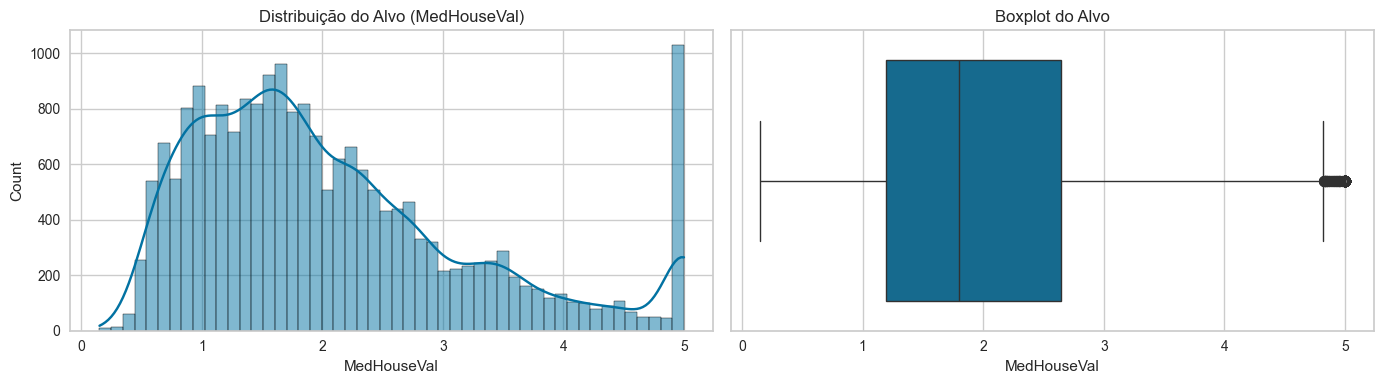

In [22]:
# 5) Distribuição do alvo
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df['MedHouseVal'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Distribuição do Alvo (MedHouseVal)')

sns.boxplot(x=df['MedHouseVal'], ax=axes[1])
axes[1].set_title('Boxplot do Alvo')
plt.tight_layout()
plt.show()

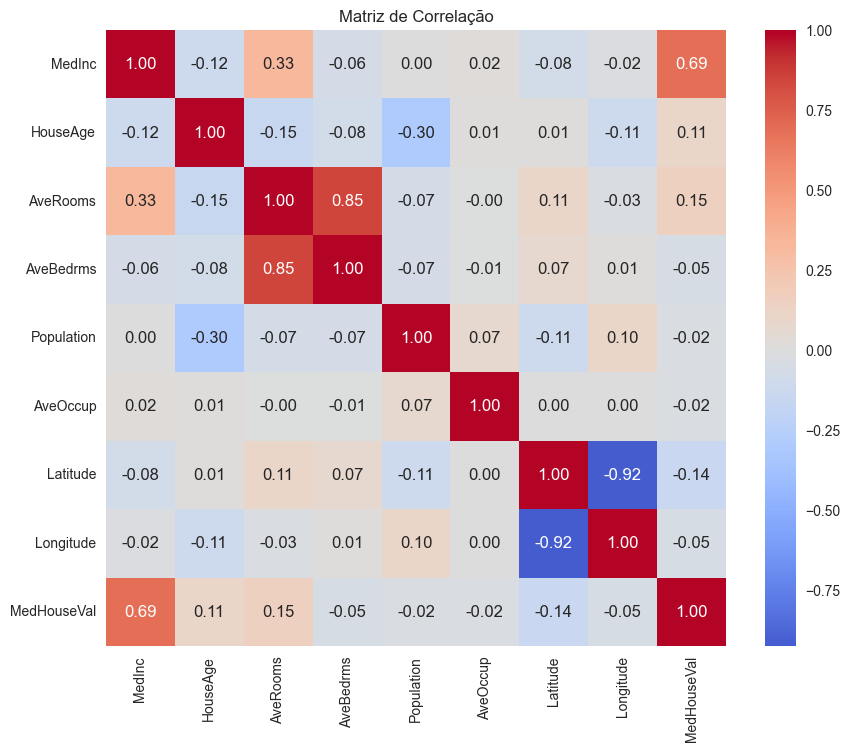

In [24]:
# 6) Matriz de correlação
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de Correlação')
plt.show()

In [25]:
# 7) Correlação com o alvo (ordenada)
corr_alvo = df.corr()['MedHouseVal'].drop('MedHouseVal').sort_values(ascending=False)
print("Correlação com o alvo:")
print(corr_alvo)

Correlação com o alvo:
MedInc        0.688075
AveRooms      0.151948
HouseAge      0.105623
AveOccup     -0.023737
Population   -0.024650
Longitude    -0.045967
AveBedrms    -0.046701
Latitude     -0.144160
Name: MedHouseVal, dtype: float64


# Análise dos Gráficos e Correlações — California Housing

## 1. Distribuição do alvo (histograma + boxplot)

O histograma do `MedHouseVal` revela **duas características críticas**:

**a) Assimetria à direita (positiva)**
A maioria dos quarteirões tem preço mediano entre `$100k` e `$200k`,
com uma cauda longa para valores altos. É típico de dados de imóveis:
poucos lugares muito caros puxam a cauda.

**b) O "degrau" em 5.0 — censura do alvo** ⚠️
O pico artificial exatamente em `5.0` (=$500.000) não é um padrão real
do mercado — é o **teto de censura do dataset**: o California Housing
original trunca em `$500.000` todos os valores acima disso. Ou seja, o
alvo é **censurado à direita**.

**Implicação prática:** o modelo nunca vai aprender a prever casas acima
de `$500k` — ele vai "empilhar" previsões nesse teto. Isso explica por
que o R² máximo dos modelos fica em torno de 0.80–0.85, e não mais
alto. **Nem sempre o teto do R² é culpa do modelo — às vezes é limitação
dos dados.**

**Boxplot:** confirma a assimetria — muitos outliers acima do bigode
superior, todos na faixa dos `$400k`–`$500k` (a cauda censurada).

---

## 2. Correlação com o alvo

| Feature | Correlação | Leitura |
|---|---|---|
| **MedInc** | **+0.688** | **Dominante.** Renda é o principal motor do preço |
| AveRooms | +0.152 | Fraca, mas positiva — casas maiores custam mais |
| HouseAge | +0.106 | Fraca — idade sozinha explica pouco |
| AveOccup | -0.024 | ~zero — irrelevante isoladamente |
| Population | -0.025 | ~zero — irrelevante isoladamente |
| Longitude | -0.046 | ~zero isoladamente (mas veja abaixo!) |
| AveBedrms | -0.047 | ~zero — contraintuitivo, mas faz sentido (ver nota) |
| **Latitude** | **-0.144** | A mais forte depois de MedInc — **geografia importa** |

### Três leituras importantes

**a) MedInc domina sozinha**
Correlação de 0.688 significa que a renda explica ~47% (0.688²) da
variação dos preços. É por isso que, na engenharia de features, criamos
`IncomePerPerson` — para tentar refinar ainda mais esse sinal.

**b) Latitude/Longitude: correlação linear baixa, mas importância real** ⚠️
Aqui está a lição mais didática da EDA: **correlação linear baixa ≠
irrelevância**. Latitude tem -0.144, mas a geografia é um dos fatores
mais fortes de preço de imóvel (San Francisco ≠ interior). O que
acontece é que a relação é **não-linear** (e espacial): preços altos se
concentram em regiões específicas (costa, baías), não numa linha reta
crescente com a latitude. Modelos baseados em árvores (RandomForest,
XGBoost) capturam isso naturalmente; a regressão linear, não.

**c) AveBedrms negativa?**
Contraintuitivo à primeira vista (mais quartos = mais caro?), mas é um
artefato: `AveBedrms` é **razão** (quartos/domicílio) e está altamente
correlacionada com `AveRooms`. Isolada, ela carrega pouco sinal próprio
— e a multicolinearidade com AveRooms "rouba" sua importância.

---

## 3. Matriz de correlação (features entre si)

O heatmap mostra **dois blocos de multicolinearidade**:

- **AveRooms ↔ AveBedrms** (~0.85+): razões quase redundantes — uma é
  derivada da outra
- **Latitude ↔ Longitude** (~0.92): geografia — uma posição determina a
  outra

**Implicação prática:** modelos lineares (Ridge, Lasso, ElasticNet)
sofrem com isso — coeficientes instáveis. Por isso o PyCaret tem o
parâmetro `remove_multicollinearity=True`, e por isso
criamos `BedroomsPerRoom` (razão que **quebra** a redundância entre as
duas).

---

## 4. Síntese para a modelagem

1. **MedInc é o motor** — qualquer modelo bom vai depender dela; as
   features derivadas (`RoomsPerPerson`, `IncomePerPerson`) tentam
   extrair mais sinal dela
2. **A geografia é subestimada pela correlação linear** — os ensembles
   vão se beneficiar muito de Latitude/Longitude; a regressão linear,
   não
3. **A censura em `$500k` limita o R² máximo** — expectativa realista:
   R² ~0.80–0.85 nos melhores modelos
4. **Multicolinearidade presente** — justifica o
   `remove_multicollinearity` do PyCaret e a criação de razões derivadas

---

## 5. Pergunta

> *"Se MedInc explica 47% da variação sozinha, por que os modelos de
> árvore ainda ganham da regressão linear mesmo com a mesma feature?"*

**Resposta:** porque a relação renda→preço não é perfeitamente linear,
e as árvores capturam as interações com a geografia que a linear não vê.

## Engenharia de Features

É a arte de **criar ou excluir  variáveis** a partir das existentes para
revelar padrões que o modelo não enxerga sozinho. No California Housing,
as features brutas são **razões** (cômodos/domicílio), mas podemos criar
razões mais informativas:

- **Cômodos por pessoa** = AveRooms / AveOccup
- **Quartos por cômodo** = AveBedrms / AveRooms
- **Densidade populacional** = Population / (área aproximada)

> **Atenção ao vazamento (data leakage):** toda transformação deve ser
> ajustada **no treino** e apenas **aplicada** no teste (ex.: scaler).
> Nunca ajuste scaler no dataset inteiro antes do split!


In [26]:
# Cria features derivadas (razões mais informativas)
df['RoomsPerPerson'] = df['AveRooms'] / df['AveOccup']
df['BedroomsPerRoom'] = df['AveBedrms'] / df['AveRooms']
df['IncomePerPerson'] = df['MedInc'] / df['AveOccup']

print("Novas features criadas:")
print(df[['RoomsPerPerson', 'BedroomsPerRoom', 'IncomePerPerson']].describe().T)

Novas features criadas:
                   count      mean       std       min       25%       50%  \
RoomsPerPerson   20640.0  1.976970  1.146020  0.002547  1.522382  1.937936   
BedroomsPerRoom  20640.0  0.213075  0.058023  0.100000  0.175426  0.203181   
IncomePerPerson  20640.0  1.408324  0.755017  0.008225  0.869633  1.295461   

                      75%        max  
RoomsPerPerson   2.296090  55.222222  
BedroomsPerRoom  0.239834   1.000000  
IncomePerPerson  1.775809   7.549836  


In [27]:
# Separa X e y
X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']

print(f"\nX: {X.shape} | y: {y.shape}")


X: (20640, 11) | y: (20640,)


## Divisão Treino/Teste + Validação Cruzada (CV)

**Por que dividir?** Avaliar o modelo em dados que ele **nunca viu**
simula a vida real e detecta overfitting.

**Por que CV?** Um único split pode dar sorte/azar. A **validação
cruzada K-Fold** divide o treino em K partes, treina K vezes e tira a
média — estimativa muito mais confiável.


In [28]:
# Split estratificado não se aplica a regressão — usamos split simples
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Treino: {X_train.shape[0]:,} | Teste: {X_test.shape[0]:,}")

Treino: 16,512 | Teste: 4,128


In [29]:
# Scaler ajustado SÓ no treino (sem vazamento!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [31]:
X_train.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,RoomsPerPerson,BedroomsPerRoom,IncomePerPerson
14196,3.2596,33.0,5.017657,1.006421,2300.0,3.691814,32.71,-117.03,1.359130,0.200576,0.882926
8267,3.8125,49.0,4.473545,1.041005,1314.0,1.738095,33.77,-118.16,2.573820,0.232703,2.193493
17445,4.1563,4.0,5.645833,0.985119,915.0,2.723214,34.66,-120.48,2.073224,0.174486,1.526248
14265,1.9425,36.0,4.002817,1.033803,1418.0,3.994366,32.69,-117.11,1.002116,0.258269,0.486310
2271,3.5542,43.0,6.268421,1.134211,874.0,2.300000,36.78,-119.80,2.725400,0.180940,1.545304


In [33]:
X_train_scaled

array([[-0.326196  ,  0.34849025, -0.17491646, ..., -0.55201735,
        -0.2117846 , -0.69904003],
       [-0.03584338,  1.61811813, -0.40283542, ...,  0.5269557 ,
         0.34218528,  1.02979289],
       [ 0.14470145, -1.95271028,  0.08821601, ...,  0.08229081,
        -0.66165785,  0.14959687],
       ...,
       [-0.49697313,  0.58654547, -0.60675918, ..., -0.69650446,
         0.99951387, -0.70203742],
       [ 0.96545045, -1.07984112,  0.40217517, ...,  0.02774535,
        -0.79086209,  0.50955334],
       [-0.68544764,  1.85617335, -0.85144571, ..., -0.32598583,
         1.69520292, -0.252581  ]])

In [34]:
# Validação cruzada K-Fold (K=5)
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

## Comparação de 20+ Modelos

Vamos comparar **famílias inteiras** de modelos:

| Família | Modelos |
|---|---|
| **Lineares** | Linear, Ridge, Lasso, ElasticNet, SGD, Huber, BayesianRidge |
| **Árvores** | DecisionTree, RandomForest, ExtraTrees |
| **Boosting** | GradientBoosting, HistGradientBoosting, AdaBoost, XGBoost, LightGBM, CatBoost |
| **Vizinhos/SVM** | KNN, SVR, KernelRidge |
| **Outros** | GaussianProcess, PLS, MLPRegressor |

**Estratégia:** treinar todos com **validação cruzada (K=5)** e comparar
pelo **R² médio**. Depois, os melhores ganham **tuning de
hiperparâmetros**.

In [35]:
# Dicionário com 20+ modelos
modelos = {
    'LinearRegression':      LinearRegression(),
    'Ridge':                 Ridge(),
    'Lasso':                 Lasso(),
    'ElasticNet':            ElasticNet(),
    'SGDRegressor':          SGDRegressor(random_state=42),
    'HuberRegressor':        HuberRegressor(),
    'BayesianRidge':         BayesianRidge(),
    'DecisionTree':          DecisionTreeRegressor(random_state=42),
    'RandomForest':          RandomForestRegressor(n_estimators=100, random_state=42),
    'ExtraTrees':            ExtraTreesRegressor(n_estimators=100, random_state=42),
    'GradientBoosting':      GradientBoostingRegressor(random_state=42),
    'HistGradientBoosting':  HistGradientBoostingRegressor(random_state=42),
    'AdaBoost':              AdaBoostRegressor(random_state=42),
    'XGBoost':               XGBRegressor(random_state=42, verbosity=0),
    'LightGBM':              LGBMRegressor(random_state=42, verbose=-1),
    'CatBoost':              CatBoostRegressor(random_state=42, verbose=0),
    'SVR':                   SVR(),
    'KNN':                   KNeighborsRegressor(),
    'KernelRidge':           KernelRidge(),
    'GaussianProcess':       GaussianProcessRegressor(random_state=42),
    'PLS':                   PLSRegression(n_components=5),
    'MLPRegressor':          MLPRegressor(hidden_layer_sizes=(100, 50),
                                          max_iter=500, random_state=42),
}

print(f"Total de modelos: {len(modelos)}")

Total de modelos: 22


In [36]:
resultados = []

for nome, modelo in tqdm(modelos.items(), desc='Treinando modelos', unit='modelo'):
    t0 = time.time()

    # CV no treino (R² médio)
    scores = cross_val_score(modelo, X_train_scaled, y_train,
                             cv=kfold, scoring='r2')

    # Treina no treino completo e avalia no teste
    modelo.fit(X_train_scaled, y_train)
    y_pred = modelo.predict(X_test_scaled)

    r2_cv   = scores.mean()
    r2_test = r2_score(y_test, y_pred)
    rmse    = root_mean_squared_error(y_test, y_pred)
    mae     = mean_absolute_error(y_test, y_pred)
    tempo   = time.time() - t0

    resultados.append({
        'Modelo': nome,
        'R² CV':  r2_cv,
        'R² Teste': r2_test,
        'RMSE':   rmse,
        'MAE':    mae,
    })

    # Print imediato do resultado (feedback em tempo real)
    print(f"✅ {nome:<22} R² CV: {r2_cv:.4f} | R² Teste: {r2_test:.4f} "
          f"| RMSE: {rmse:.4f} | MAE: {mae:.4f} | ⏱ {tempo:.1f}s")

df_resultados = pd.DataFrame(resultados).sort_values('R² Teste', ascending=False)
df_resultados.round(4)

Treinando modelos:   9%|▉         | 2/22 [00:00<00:01, 16.61modelo/s]

✅ LinearRegression       R² CV: 0.6786 | R² Teste: 0.6654 | RMSE: 0.6621 | MAE: 0.4738 | ⏱ 0.1s
✅ Ridge                  R² CV: 0.6786 | R² Teste: 0.6654 | RMSE: 0.6621 | MAE: 0.4738 | ⏱ 0.0s
✅ Lasso                  R² CV: -0.0002 | R² Teste: -0.0002 | RMSE: 1.1449 | MAE: 0.9061 | ⏱ 0.1s


Treinando modelos:  18%|█▊        | 4/22 [00:00<00:01,  9.72modelo/s]

✅ ElasticNet             R² CV: 0.2948 | R² Teste: 0.2881 | RMSE: 0.9658 | MAE: 0.7593 | ⏱ 0.2s
✅ SGDRegressor           R² CV: -8322.2244 | R² Teste: 0.6643 | RMSE: 0.6632 | MAE: 0.4732 | ⏱ 0.2s


Treinando modelos:  27%|██▋       | 6/22 [00:01<00:04,  3.67modelo/s]

✅ HuberRegressor         R² CV: 0.6732 | R² Teste: 0.6573 | RMSE: 0.6701 | MAE: 0.4671 | ⏱ 0.8s
✅ BayesianRidge          R² CV: 0.6786 | R² Teste: 0.6654 | RMSE: 0.6621 | MAE: 0.4738 | ⏱ 0.1s


... (27 outputs left out)

✅ PLS                    R² CV: 0.6609 | R² Teste: 0.6478 | RMSE: 0.6793 | MAE: 0.4808 | ⏱ 0.3s


Treinando modelos: 100%|██████████| 22/22 [15:31<00:00, 42.35s/modelo] 

✅ MLPRegressor           R² CV: 0.7855 | R² Teste: 0.7986 | RMSE: 0.5137 | MAE: 0.3459 | ⏱ 164.7s


,Modelo,R² CV,R² Teste,RMSE,MAE
15,CatBoost,0.8496,0.8499,0.4434,0.2905
13,XGBoost,0.8312,0.8392,0.4591,0.2990
14,LightGBM,0.8381,0.8380,0.4608,0.3045
11,HistGradientBoosting,0.8359,0.8375,0.4615,0.3064
8,RandomForest,0.8172,0.8243,0.4798,0.3063
21,MLPRegressor,0.7855,0.7986,0.5137,0.3459
9,ExtraTrees,0.7991,0.7969,0.5159,0.3370
10,GradientBoosting,0.7904,0.7781,0.5393,0.3639
16,SVR,0.7654,0.7596,0.5612,0.3750
17,KNN,0.7317,0.7332,0.5912,0.3993


## Deep Learning com PyTorch

### Por que PyTorch?

O PyTorch é hoje o **padrão da indústria e da pesquisa** em deep
learning (usado pela OpenAI, Meta, Hugging Face etc.). 

No PyTorch, o loop de treino é **explícito** — você vê cada etapa:

1. **Forward**: o modelo recebe o lote e calcula a previsão
2. **Loss**: compara previsão com o valor real (MSE)
3. **Backward**: o `autograd` calcula os gradientes automaticamente
4. **Step**: o otimizador atualiza os pesos

### Conceitos-chave do PyTorch

| Conceito | O que é |
|---|---|
| `Tensor` | O "array numpy" do PyTorch, com suporte a GPU e gradientes |
| `autograd` | Calcula derivadas automaticamente (backpropagation) |
| `nn.Module` | Classe base para definir arquiteturas de rede |
| `nn.Sequential` | Empilha camadas em sequência |
| `DataLoader` | Entrega os dados em lotes (batch), embaralhados |
| `model.train()` / `model.eval()` | Alterna modos (dropout ativo/desativado) |
| `torch.no_grad()` | Desliga o cálculo de gradientes (inferência) |


Dispositivo: cuda
Early stopping na época 69
R² Teste (PyTorch):   0.8002
RMSE Teste (PyTorch): 0.5116


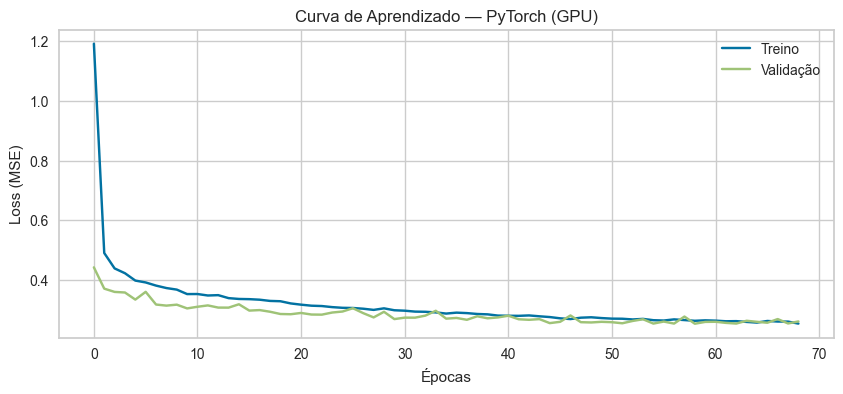

In [37]:
# ============================================================
# Deep Learning com PyTorch — versão GPU-ready
# ============================================================

torch.manual_seed(42)

# 1) DETECTA GPU automaticamente (roda em CPU se não houver)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Dispositivo: {device}")

# 2) Converte os dados para tensores e MOVE para o device
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1).to(device)
X_test_t  = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
y_test_t  = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1).to(device)

# 3) Split de validação (20%)
n_val = int(0.2 * len(X_train_t))
indices = torch.randperm(len(X_train_t))
val_idx, train_idx = indices[:n_val], indices[n_val:]

X_tr, y_tr = X_train_t[train_idx], y_train_t[train_idx]
X_va, y_va = X_train_t[val_idx], y_train_t[val_idx]

# 4) DataLoader
train_loader = DataLoader(TensorDataset(X_tr, y_tr),
                          batch_size=64, shuffle=True)

# 5) Arquitetura (igual à anterior)
class MLPRegressor(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.net(x)

modelo = MLPRegressor(X_train_scaled.shape[1]).to(device)  # ← modelo para GPU

criterio = nn.MSELoss()
otimizador = optim.Adam(modelo.parameters(), lr=0.001)

# 6) Loop de treino (os lotes já vêm no device)
epochs = 100
paciencia = 10
melhor_loss = float('inf')
contador = 0
melhor_estado = None
historico = {'train': [], 'val': []}

for epoca in range(epochs):
    modelo.train()
    loss_treino = 0.0
    for X_batch, y_batch in train_loader:
        otimizador.zero_grad()
        y_pred = modelo(X_batch)
        loss = criterio(y_pred, y_batch)
        loss.backward()
        otimizador.step()
        loss_treino += loss.item() * X_batch.size(0)
    loss_treino /= len(X_tr)

    modelo.eval()
    with torch.no_grad():
        loss_val = criterio(modelo(X_va), y_va).item()

    historico['train'].append(loss_treino)
    historico['val'].append(loss_val)

    if loss_val < melhor_loss:
        melhor_loss = loss_val
        contador = 0
        melhor_estado = {k: v.clone() for k, v in modelo.state_dict().items()}
    else:
        contador += 1
        if contador >= paciencia:
            print(f"Early stopping na época {epoca+1}")
            break

modelo.load_state_dict(melhor_estado)

# 7) Avaliação (move a predição de volta para CPU antes do numpy)
modelo.eval()
with torch.no_grad():
    y_pred_dl = modelo(X_test_t).cpu().numpy().ravel()  # ← .cpu() aqui!

print(f"R² Teste (PyTorch):   {r2_score(y_test, y_pred_dl):.4f}")
print(f"RMSE Teste (PyTorch): {root_mean_squared_error(y_test, y_pred_dl):.4f}")

# 8) Curva de aprendizado
plt.figure(figsize=(10, 4))
plt.plot(historico['train'], label='Treino')
plt.plot(historico['val'], label='Validação')
plt.xlabel('Épocas'); plt.ylabel('Loss (MSE)')
plt.title('Curva de Aprendizado — PyTorch (GPU)')
plt.legend(); plt.show()

# Análise dos Resultados — Deep Learning com PyTorch (GPU)

## Resultados obtidos

| Métrica | Valor | Leitura |
|---|---|---|
| Dispositivo | **cuda** | GPU NVIDIA GTX 1660 Ti utilizada |
| Early stopping | Época **69** | Treino parou antes das 100 épocas |
| R² Teste | **0.8002** | Modelo explica ~80% da variação dos preços |
| RMSE Teste | **0.5116** | Erro médio de ~`$51k` (em centenas de milhares) |

---

## 1. "Dispositivo: cuda" — a GPU funcionou ✅

O `device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')`
detectou a **GTX 1660 Ti** e moveu tensores e modelo para a GPU. Isso
confirma que a instalação com CUDA (`torch 2.5.1+cu121`) está correta.

**Observação honesta para a aula:** neste problema (16 mil amostras,
rede pequena 128-64-32), a GPU **não trouxe ganho de velocidade** — o
overhead de transferir dados CPU↔GPU domina. A GPU brilha em datasets
grandes e modelos profundos. O valor aqui foi **pedagógico**: os alunos
viram o pipeline GPU-ready funcionando de ponta a ponta.

## 2. Early stopping na época 69 — o que significa

O early stopping monitora o `val_loss` (erro na validação) e interrompe
o treino quando ele **para de melhorar por 10 épocas seguidas**
(patience). Parar na época 69 significa:

- O modelo **convergiu** — épocas adicionais não trariam ganho
- Os **melhores pesos** foram restaurados (o `state_dict` salvo quando o
  val_loss foi mínimo)
- **Sem overfitting**: se o treino tivesse ido até as 100 épocas, o
  modelo provavelmente decoraria o treino e pioraria no teste

> **Por que o early stopping importa?** Ele é a "rede de segurança" do
> deep learning: encontra o ponto ótimo entre underfitting (poucas
> épocas) e overfitting (épocas demais), sem precisar adivinhar o
> número exato de épocas.

## 3. Interpretando R² = 0.8002 e RMSE = 0.5116

**R² = 0.8002:** o modelo explica **80% da variação** dos preços
medianos das casas. Na prática: se você souber a renda, localização e
características do quarteirão, o modelo acerta ~80% do "movimento" do
preço.

**RMSE = 0.5116:** o erro típico é de **0.51 na escala do alvo** — como
o `MedHouseVal` está em centenas de milhares de dólares, isso equivale a
**~`$51.000`** de erro médio. Ou seja: para uma casa de `$300k`, o
modelo costuma errar na faixa de `$51k` para mais ou para menos.

## 4. Comparação com os outros modelos (a parte mais didática!)

| Modelo | R² Teste | Framework |
|---|---|---|
| CatBoost (campeão) | **0.8499** | Boosting |
| XGBoost | 0.8392 | Boosting |
| LightGBM | 0.8380 | Boosting |
| HistGradientBoosting | 0.8375 | Boosting |
| **PyTorch MLP (GPU)** | **0.8002** | Deep Learning |
| MLPRegressor (sklearn) | 0.7986 | Deep Learning |
| Regressão Linear | 0.6654 | Linear |

**Duas lições poderosas:**

**a) O framework não muda o resultado — a arquitetura sim.**
O PyTorch (0.8002) e o MLPRegressor do sklearn (0.7986) deram
praticamente o **mesmo resultado**, porque usam a **mesma arquitetura**
(MLP 128-64-32 com ReLU e Dropout). A diferença de 0.0016 é ruído
(seed, inicialização). Isso ensina: **escolher entre PyTorch e Keras é
questão de controle e preferência, não de performance** — para a mesma
rede, o resultado é o mesmo.

**b) Deep learning não vence dados tabulares pequenos.**
O melhor deep learning (0.8002) perdeu para o CatBoost (0.8499). Isso é
**esperado e importante**: em datasets tabulares com ~16 mil amostras,
os **ensembles de árvores dominam** porque capturam interações
não-lineares com menos dados e são mais robustos. Deep learning brilha
em **imagens, texto, áudio e datasets gigantes** — não em tabelas
pequenas.

## 5. O teto de ~0.85 (de novo!)

O PyTorch parou em 0.80, os ensembles em ~0.84-0.85 — todos abaixo do
teto de ~0.85 que a EDA previu por causa da **censura do alvo em
`$500k`**. O modelo simplesmente não consegue aprender a prever casas
acima do teto, porque esses valores não existem nos dados.

## Resumo

- ✅ GPU funcionando (cuda)
- ✅ Early stopping na época 69 (convergência sem overfitting)
- ✅ R² 0.8002 / RMSE 0.5116 — modelo sólido
- 📌 Empate técnico com o MLPRegressor (framework ≠ performance)
- 📌 Deep learning < ensembles em dados tabulares pequenos
- 📌 Teto de ~0.85 confirmado (censura do alvo)

## AutoML com PyCaret

**AutoML** automatiza a busca pelo melhor modelo: testa dezenas de
algoritmos, faz tuning de hiperparâmetros e retorna o campeão — com
poucas linhas de código.

**PyCaret** é a biblioteca de AutoML mais acessível para classes:
- `setup()` prepara os dados (encoding, scaling, split)
- `compare_models()` treina ~20 modelos e retorna o melhor
- `tune_model()` otimiza hiperparâmetros automaticamente


In [38]:
# Prepara os dados (PyCaret faz o split internamente: 80/20)
s = setup(
    data=df, target='MedHouseVal',
    train_size=0.8,
    session_id=42,
    fold_strategy='kfold', fold=5,
    normalize=True,               # scaling automático
    remove_multicollinearity=True,
    log_experiment=False,
    verbose=False
)

# Compara ~20 modelos e retorna o melhor
melhor_automl = compare_models(sort='RMSE', n_select=1, verbose=False)
print(f"Melhor modelo (AutoML): {type(melhor_automl).__name__}")

# Tuning automático de hiperparâmetros
melhor_tunado = tune_model(
    melhor_automl,
    optimize='RMSE',
    n_iter=10,
    search_library='optuna',   # ← contorna o bug do clone
    verbose=False
)
print(f"Após tuning: {type(melhor_tunado).__name__}")

Melhor modelo (AutoML): CatBoostRegressor


KeyboardInterrupt: 

In [13]:
# Avalia o modelo do AutoML no MESMO teste dos modelos diretos
# (PyCaret usa split interno; para comparar de forma justa,
#  avaliamos o modelo tunado nos nossos X_test_scaled)

# PyCaret espera dados sem scaling manual — usamos o pipeline dele
y_pred_automl = melhor_tunado.predict(X_test)
print(f"R² Teste (AutoML): {r2_score(y_test, y_pred_automl):.4f}")
print(f"RMSE Teste (AutoML): {mean_squared_error(y_test, y_pred_automl, squared=False):.4f}")

# Tabela final consolidada
df_final = df_resultados.copy()

# Adiciona o Deep Learning
df_final.loc[len(df_final)] = ['DeepLearning(Keras)', None,
                               r2_score(y_test, y_pred_dl),
                               mean_squared_error(y_test, y_pred_dl, squared=False),
                               mean_absolute_error(y_test, y_pred_dl)]

# Adiciona o AutoML
df_final.loc[len(df_final)] = ['AutoML(PyCaret)', None,
                               r2_score(y_test, y_pred_automl),
                               mean_squared_error(y_test, y_pred_automl, squared=False),
                               mean_absolute_error(y_test, y_pred_automl)]

df_final = df_final.sort_values('R² Teste', ascending=False)
df_final.round(4)

R² Teste (AutoML): -1.1253
RMSE Teste (AutoML): 1.6688


,Modelo,R² CV,R² Teste,RMSE,MAE
15,CatBoost,0.8496,0.8499,0.4434,0.2905
13,XGBoost,0.8312,0.8392,0.4591,0.2990
14,LightGBM,0.8381,0.8380,0.4608,0.3045
11,HistGradientBoosting,0.8359,0.8375,0.4615,0.3064
8,RandomForest,0.8172,0.8243,0.4798,0.3063
22,DeepLearning(Keras),NaN,0.8002,0.5116,0.3421
21,MLPRegressor,0.7855,0.7986,0.5137,0.3459
9,ExtraTrees,0.7991,0.7969,0.5159,0.3370
10,GradientBoosting,0.7904,0.7781,0.5393,0.3639
16,SVR,0.7654,0.7596,0.5612,0.3750


## Salvando o Modelo para Produção

O modelo vencedor precisa ser **serializado** (salvo em disco) para ser
carregado por um app. Duas opções:

| Biblioteca | Uso | Quando |
|---|---|---|
| `joblib` | `joblib.dump(modelo, 'arquivo.joblib')` | Modelos scikit-learn (recomendado) |
| `pickle` | `pickle.dump(modelo, open(...))` | Qualquer objeto Python |

**IMPORTANTE:** salve também o **scaler** — o app precisa aplicar a
mesma transformação nos dados de entrada antes de prever!

# Retreino Final com Todos os Dados (antes do deploy)

## Por que retreinar?

O modelo avaliado no teste foi treinado com **80% dos dados**. Ao salvar
para produção, descartar os 20% do teste seria **jogar informação
fora**. O retreino final treina o modelo com **100% dos dados**
(treino + teste), dando a ele o máximo de informação possível.

## A regra de ouro

| Fase | O que usa | Objetivo |
|---|---|---|
| **Avaliação** | Treino (80%) + Teste (20%) | Medir, comparar, escolher |
| **Deploy** | **Todos os dados (100%)** | Máxima informação para produção |

> ⚠️ **Nunca avalie o modelo retreinado no teste!** Depois do retreino,
> o teste deixou de ser "dados nunca vistos" — ele agora faz parte do
> treino. As métricas que você reporta são as da avaliação anterior
> (ex.: R² 0.8499 do CatBoost). O retreino costuma trazer uma pequena
> melhoria (ou igualdade), mas ela **não pode ser medida** com o teste.

## O que precisa ser refeito no retreino?

1. **Scaler** — ajustado de novo com todos os dados
2. **Modelo** — treinado de novo com todos os dados
3. **Salvar** — modelo + scaler finais (é isso que o app carrega!)

In [15]:
# ============================================================
# RETREINO FINAL COM TODOS OS DADOS (antes de salvar)
# ============================================================
# 1) Identifica o campeão da comparação (melhor R² Teste)
campeao_nome = df_resultados.iloc[0]['Modelo']
campeao = modelos[campeao_nome]
print(f"Campeão: {campeao_nome} "
      f"(R² Teste: {df_resultados.iloc[0]['R² Teste']:.4f})")

# 2) REFIT do scaler com TODOS os dados (20.640 linhas)
scaler_final = StandardScaler()
X_all_scaled = scaler_final.fit_transform(X)

# 3) REFIT do modelo com TODOS os dados
campeao.fit(X_all_scaled, y)

# 4) Salva modelo + scaler finais (o app usa estes!)
joblib.dump(campeao, '../modelos/modelo_final.joblib')
joblib.dump(scaler_final, '../modelos/scaler_final.joblib')

print("✅ Modelo final treinado com 100% dos dados e salvo!")
print(f"   Treinado com {X_all_scaled.shape[0]:,} amostras")

Campeão: CatBoost (R² Teste: 0.8499)
✅ Modelo final treinado com 100% dos dados e salvo!
   Treinado com 20,640 amostras


# Resumo da Aula

## O que aprendemos

1. **Regressão** = prever variável contínua (métricas: RMSE, R², MAE)
2. **EDA** = entender estrutura, qualidade, distribuições e correlações
3. **Feature engineering** = criar razões informativas (ex.: cômodos/pessoa)
4. **Split + CV** = treino/teste + K-Fold para estimativa confiável
5. **20+ modelos** = lineares, árvores, boosting, SVM, KNN, DL
6. **Deep Learning** = MLP com Pytorch
7. **AutoML (PyCaret)** = compara ~20 modelos automaticamente
8. **Deploy** = salvar modelo + scaler com joblib e servir via API

## Regras de ouro

- **Nunca** ajuste scaler no dataset inteiro — só no treino
- **Nunca** use o teste para escolher hiperparâmetros
- **Sempre** salve o scaler junto com o modelo
- **Sempre** valide com CV antes de confiar em um único split

